# 09 Report figures
Every figure used in the report is regenerated here from saved results and code. Run after notebooks 01-08. Files go to `../figures/`.

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_dataset, split_data

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
THRESH = {"telco": 0.36, "bank": 0.32}
TITLE = {"telco": "Telco", "bank": "Bank"}

## Fig A. Model comparison (cross-validated PR-AUC)

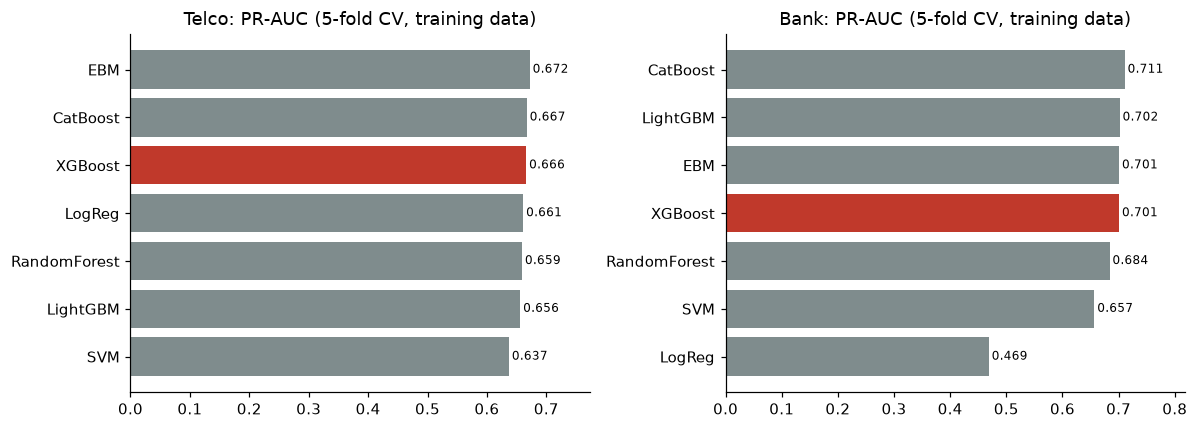

In [2]:
m = pd.read_csv("../results/model_comparison_all.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=False)
for a, name in zip(ax, ["telco", "bank"]):
    d = m[m["dataset"] == name].sort_values("pr_auc")
    colors = ["#c0392b" if mod == "XGBoost" else "#7f8c8d" for mod in d["model"]]
    a.barh(d["model"], d["pr_auc"], color=colors)
    for y, v in enumerate(d["pr_auc"]):
        a.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8)
    a.set_title(f"{TITLE[name]}: PR-AUC (5-fold CV, training data)")
    a.set_xlim(0, d["pr_auc"].max() * 1.15)
plt.tight_layout(); plt.savefig("../figures/fig_model_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

## Fig B. Churn rate by SHAP-based segment

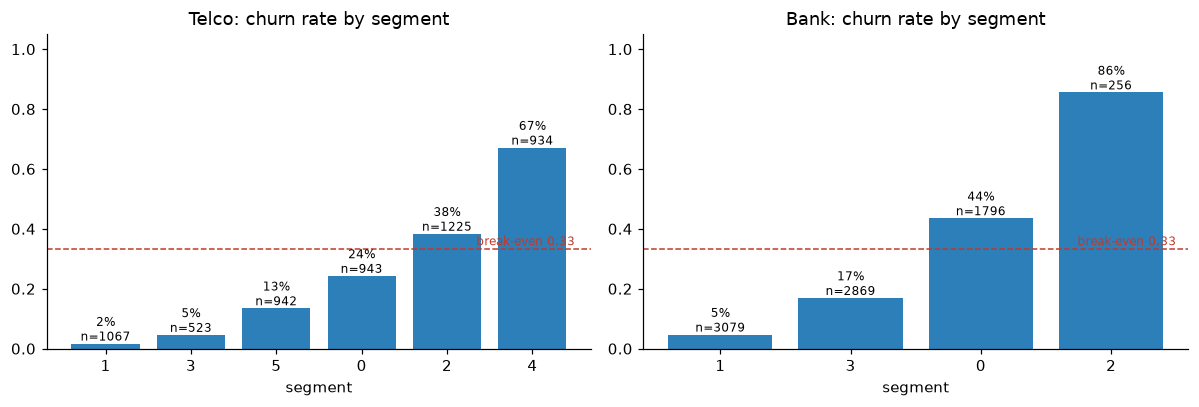

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, name in zip(ax, ["telco", "bank"]):
    seg = pd.read_csv(f"../results/segments_{name}.csv", index_col=0)
    t = seg.groupby("shap_segment")["churn"].agg(["size", "mean"]).sort_values("mean")
    a.bar(t.index.astype(str), t["mean"], color="#2c7fb8")
    for i, (n, r) in enumerate(zip(t["size"], t["mean"])):
        a.text(i, r + 0.01, f"{r:.0%}\nn={n}", ha="center", fontsize=8)
    a.axhline(0.333, color="#c0392b", ls="--", lw=1); a.text(len(t) - 0.5, 0.345, "break-even 0.33", color="#c0392b", ha="right", fontsize=8)
    a.set_title(f"{TITLE[name]}: churn rate by segment"); a.set_xlabel("segment"); a.set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig("../figures/fig_segment_churn.png", dpi=200, bbox_inches="tight"); plt.show()

## Fig C. False negatives: share of churners missed, by segment

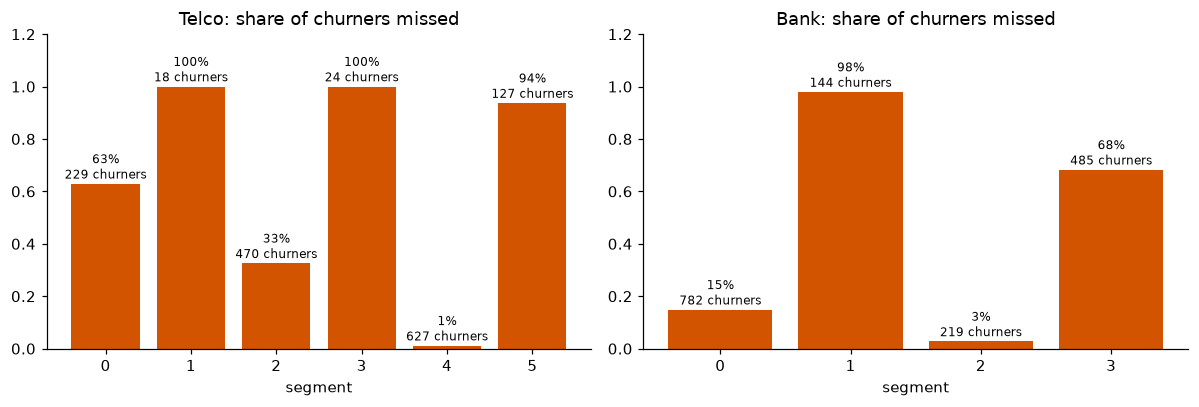

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, name in zip(ax, ["telco", "bank"]):
    seg = pd.read_csv(f"../results/segments_{name}.csv", index_col=0)
    proba = pd.read_csv(f"../results/oof_xgb_{name}.csv")["proba"].values
    d = pd.DataFrame({"segment": seg["shap_segment"].values, "churn": seg["churn"].values, "proba": proba})
    d = d[d["churn"] == 1]
    d["missed"] = d["proba"] < THRESH[name]
    t = d.groupby("segment")["missed"].agg(["size", "mean"])
    a.bar(t.index.astype(str), t["mean"], color="#d35400")
    for i, (n, r) in enumerate(zip(t["size"], t["mean"])):
        a.text(i, r + 0.02, f"{r:.0%}\n{n} churners", ha="center", fontsize=8)
    a.set_title(f"{TITLE[name]}: share of churners missed"); a.set_xlabel("segment"); a.set_ylim(0, 1.2)
plt.tight_layout(); plt.savefig("../figures/fig_false_negatives_by_segment.png", dpi=200, bbox_inches="tight"); plt.show()

## Fig D. Survival curves by contract (Kaplan-Meier, Telco training data)

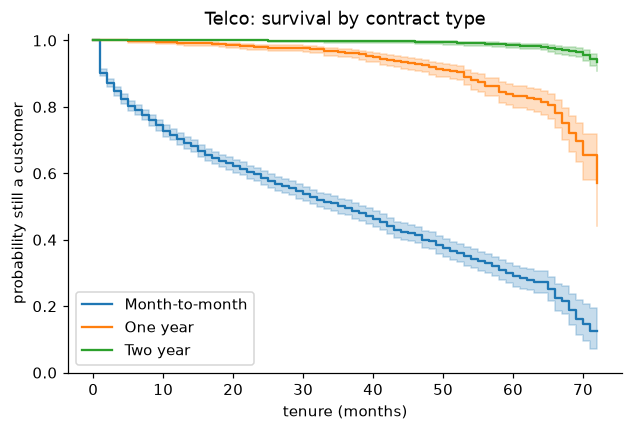

In [5]:
from lifelines import KaplanMeierFitter

X_train, X_test, y_train, y_test = split_data(load_dataset("telco"))
time = X_train["tenure"].clip(lower=0.5)
fig, ax = plt.subplots(figsize=(6.5, 4))
for contract in ["Month-to-month", "One year", "Two year"]:
    mask = (X_train["Contract"] == contract).values
    KaplanMeierFitter().fit(time[mask], y_train[mask], label=contract).plot_survival_function(ax=ax, ci_show=True)
ax.set_xlabel("tenure (months)"); ax.set_ylabel("probability still a customer")
ax.set_title("Telco: survival by contract type"); ax.set_ylim(0, 1.02)
plt.savefig("../figures/fig_survival_by_contract.png", dpi=200, bbox_inches="tight"); plt.show()

## Fig E. Survival model comparison
Values are the 5-fold cross-validation results printed by `08_survival.ipynb` (recorded in decisions log entry 20).

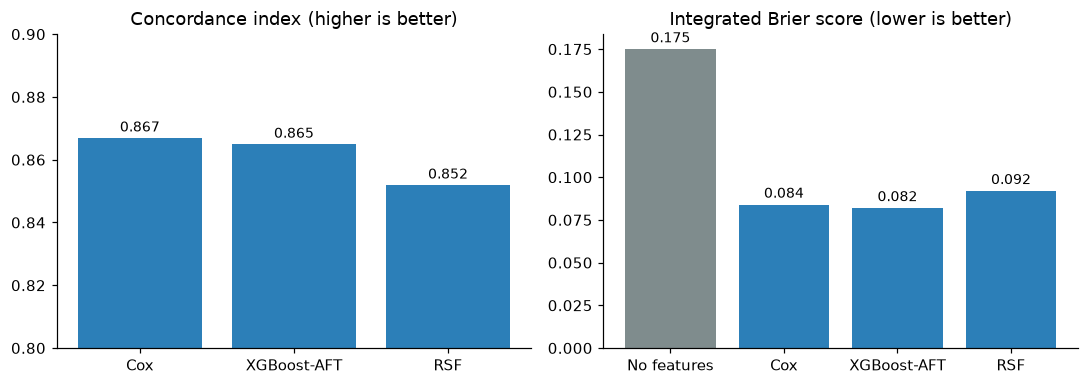

In [6]:
models = ["Cox", "XGBoost-AFT", "RSF"]
cidx = [0.867, 0.865, 0.852]
ibs = {"No features": 0.175, "Cox": 0.084, "XGBoost-AFT": 0.082, "RSF": 0.092}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(models, cidx, color="#2c7fb8"); ax[0].set_ylim(0.8, 0.9); ax[0].set_title("Concordance index (higher is better)")
for i, v in enumerate(cidx): ax[0].text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
ax[1].bar(list(ibs), list(ibs.values()), color=["#7f8c8d", "#2c7fb8", "#2c7fb8", "#2c7fb8"]); ax[1].set_title("Integrated Brier score (lower is better)")
for i, v in enumerate(ibs.values()): ax[1].text(i, v + 0.004, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig("../figures/fig_survival_models.png", dpi=200, bbox_inches="tight"); plt.show()

## Fig F. Customer-specific lifetime value (Telco)

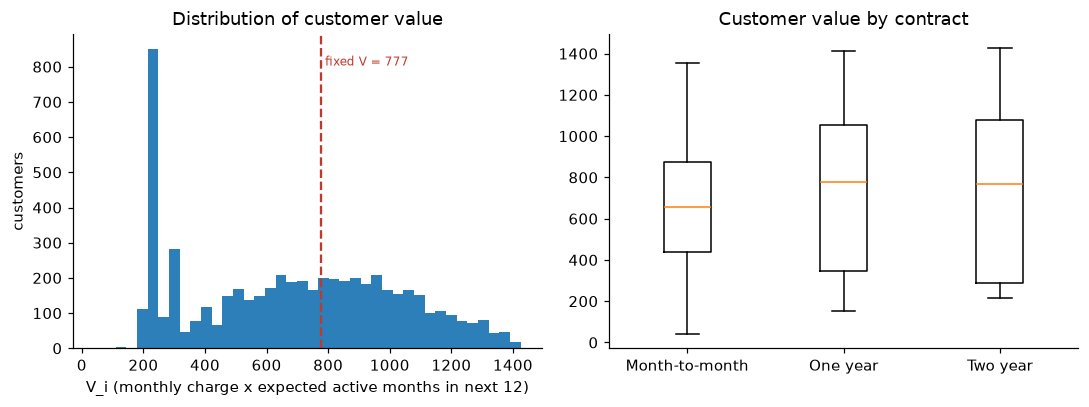

In [7]:
lv = pd.read_csv("../results/lifetime_value_telco.csv", index_col=0)
contract = X_train.loc[lv.index, "Contract"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist(lv["V_i"], bins=40, color="#2c7fb8")
ax[0].axvline(777, color="#c0392b", ls="--"); ax[0].text(790, ax[0].get_ylim()[1] * 0.9, "fixed V = 777", color="#c0392b", fontsize=8)
ax[0].set_xlabel("V_i (monthly charge x expected active months in next 12)"); ax[0].set_ylabel("customers")
ax[0].set_title("Distribution of customer value")
order = ["Month-to-month", "One year", "Two year"]
ax[1].boxplot([lv.loc[contract == c, "V_i"] for c in order], showfliers=False)
ax[1].set_xticklabels(order)
ax[1].set_title("Customer value by contract")
plt.tight_layout(); plt.savefig("../figures/fig_lifetime_value.png", dpi=200, bbox_inches="tight"); plt.show()